# Activity 2: Binary Classification using Logistic Regression

**Dataset:** Breast Cancer Wisconsin (Diagnostic)  
**Target:** Diagnosis — Malignant (1) or Benign (0)  
**Goal:** Predict whether a tumour is malignant or benign using Logistic Regression.



## 1. Import libraries

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, classification_report, roc_curve, roc_auc_score
)
from sklearn.dummy import DummyClassifier

## 2. Load the dataset

In [20]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)

# In the original dataset: 0 = malignant, 1 = benign.
# Here, 1 means malignant and 0 means benign.
y = (data.target == 0).astype(int)

df = X.copy()
df['diagnosis'] = pd.Series(y).map({0: 'Benign', 1: 'Malignant'})

print("Rows and columns:", df.shape)
print(df.head())

Rows and columns: (569, 31)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  

## 3. Understand and check the data

In [21]:
print("Data types:")
print(X.dtypes)

print("\\nSummary statistics:")
print(X.describe())

print("\\nMissing values:", X.isnull().sum().sum())
print("Duplicate rows:", X.duplicated().sum())

print("\\nClass counts:")
print(df['diagnosis'].value_counts())

Data types:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst sy

## 4. Show class distribution

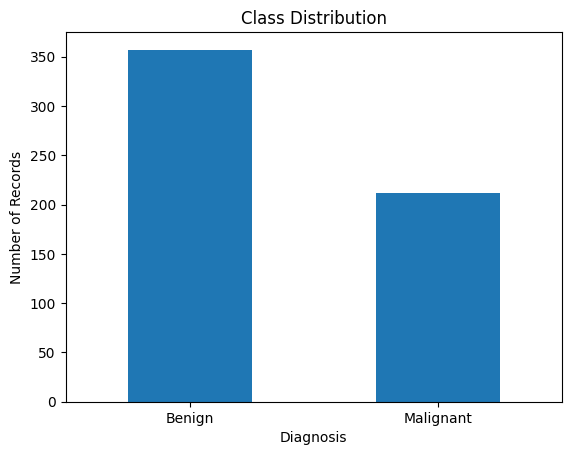

In [22]:
df['diagnosis'].value_counts().plot(kind='bar')
plt.title('Class Distribution')
plt.xlabel('Diagnosis')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.show()

## 5. Split the data (80:20)

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class counts:")
print(pd.Series(y_train).value_counts())

print("\nTesting class counts:")
print(pd.Series(y_test).value_counts())

Training records: 455
Testing records: 114

Training class counts:
0    285
1    170
Name: count, dtype: int64

Testing class counts:
0    72
1    42
Name: count, dtype: int64


## 6. Scale the features

In [24]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features scaled successfully.")

Features scaled successfully.


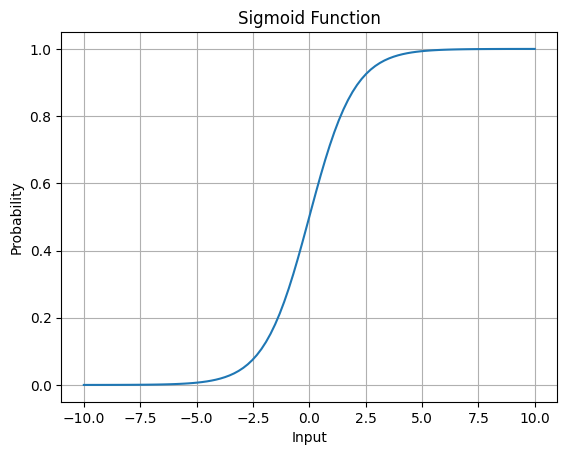

In [25]:
z = np.linspace(-10, 10, 100)
sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)
plt.title('Sigmoid Function')
plt.xlabel('Input')
plt.ylabel('Probability')
plt.grid()
plt.show()

## 8. Train Logistic Regression

In [26]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

print("Intercept:", model.intercept_[0])

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

print(coefficients)

Intercept: -0.24300532690559115
                    Feature  Coefficient
0               mean radius     0.361150
1              mean texture     0.482219
2            mean perimeter     0.353160
3                 mean area     0.439950
4           mean smoothness     0.350622
5          mean compactness    -0.439546
6            mean concavity     0.782298
7       mean concave points     0.952813
8             mean symmetry    -0.163991
9    mean fractal dimension    -0.080865
10             radius error     1.233325
11            texture error    -0.407611
12          perimeter error     0.748295
13               area error     0.909029
14         smoothness error     0.247991
15        compactness error    -0.906925
16          concavity error    -0.092341
17     concave points error     0.482089
18           symmetry error    -0.330658
19  fractal dimension error    -0.593876
20             worst radius     0.896968
21            worst texture     1.434093
22          worst perimet

## 9. Predict probabilities and labels

In [29]:
probabilities = model.predict_proba(X_test_scaled)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

results = pd.DataFrame({
    'Actual': pd.Series(y_test).map({0: 'Benign', 1: 'Malignant'}).values,
    'Predicted Probability (Malignant)': probabilities,
    'Predicted Class': pd.Series(predictions).map({0: 'Benign', 1: 'Malignant'}).values
})

print(results.head(10))

      Actual  Predicted Probability (Malignant) Predicted Class
0     Benign                           0.000365          Benign
1  Malignant                           1.000000       Malignant
2     Benign                           0.042568          Benign
3  Malignant                           0.576187       Malignant
4     Benign                           0.509155       Malignant
5     Benign                           0.000616          Benign
6  Malignant                           0.761534       Malignant
7     Benign                           0.001012          Benign
8     Benign                           0.000569          Benign
9     Benign                           0.010768          Benign


## 10. Compare decision thresholds

In [30]:
for threshold in [0.3, 0.5, 0.7]:
    pred = (probabilities >= threshold).astype(int)
    print("Threshold:", threshold,
          "| Predicted malignant:", pred.sum(),
          "| Accuracy:", round(accuracy_score(y_test, pred), 3),
          "| Precision:", round(precision_score(y_test, pred, zero_division=0), 3),
          "| Recall:", round(recall_score(y_test, pred, zero_division=0), 3),
          "| F1:", round(f1_score(y_test, pred, zero_division=0), 3))

Threshold: 0.3 | Predicted malignant: 42 | Accuracy: 0.982 | Precision: 0.976 | Recall: 0.976 | F1: 0.976
Threshold: 0.5 | Predicted malignant: 40 | Accuracy: 0.965 | Precision: 0.975 | Recall: 0.929 | F1: 0.951
Threshold: 0.7 | Predicted malignant: 38 | Accuracy: 0.965 | Precision: 1.0 | Recall: 0.905 | F1: 0.95


## 11. Confusion matrix and classification metrics (threshold 0.5)

In [31]:
cm = confusion_matrix(y_test, predictions)
tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)

print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, predictions)

print("\\nAccuracy:", accuracy)
print("Precision:", precision)
print("Recall (Sensitivity):", recall)
print("Specificity:", specificity)
print("F1 Score:", f1)

print("\\nClassification Report:")
print(classification_report(y_test, predictions, target_names=['Benign', 'Malignant']))

Confusion Matrix:
[[71  1]
 [ 3 39]]
TN: 71
FP: 1
FN: 3
TP: 39
\nAccuracy: 0.9649122807017544
Precision: 0.975
Recall (Sensitivity): 0.9285714285714286
Specificity: 0.9861111111111112
F1 Score: 0.9512195121951219
\nClassification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## 12. Compare with majority-class baseline

In [32]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train_scaled, y_train)
baseline_predictions = baseline.predict(X_test_scaled)

print("Logistic Regression accuracy:", accuracy)
print("Majority-class baseline accuracy:", accuracy_score(y_test, baseline_predictions))

Logistic Regression accuracy: 0.9649122807017544
Majority-class baseline accuracy: 0.631578947368421


## 13. ROC curve and ROC-AUC

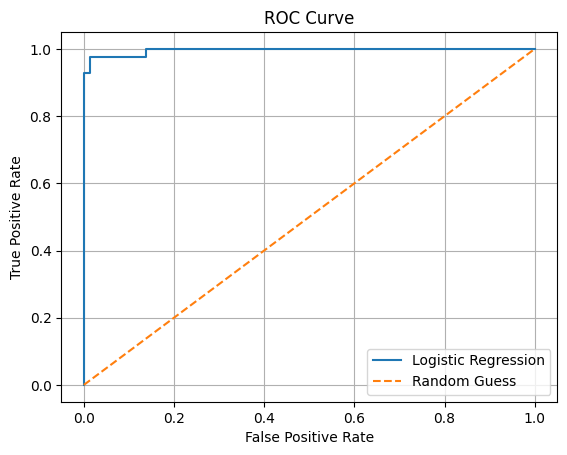

ROC-AUC: 0.996031746031746


In [33]:
fpr, tpr, thresholds = roc_curve(y_test, probabilities)
auc = roc_auc_score(y_test, probabilities)

plt.plot(fpr, tpr, label='Logistic Regression')
plt.plot([0, 1], [0, 1], '--', label='Random Guess')
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC:", auc)

## 14. Compare training and testing performance

In [34]:
train_predictions = model.predict(X_train_scaled)
test_predictions = model.predict(X_test_scaled)

print("Training accuracy:", accuracy_score(y_train, train_predictions))
print("Testing accuracy:", accuracy_score(y_test, test_predictions))

Training accuracy: 0.9868131868131869
Testing accuracy: 0.9649122807017544


## 15. Visualise decision behaviour using one feature

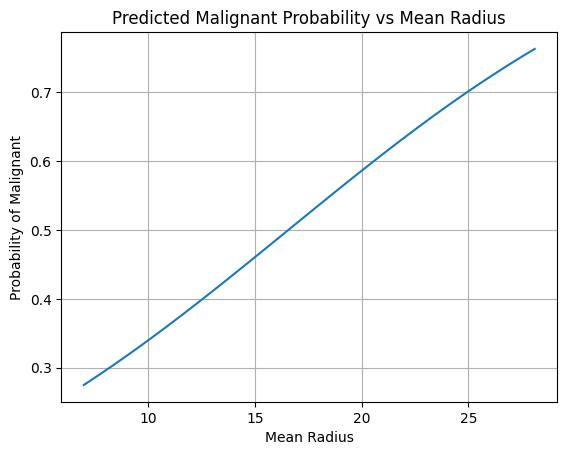

In [35]:
feature = 'mean radius'
feature_index = list(X.columns).index(feature)

# Keep other features at their average scaled value (approximately zero)
sample_points = np.linspace(
    X[feature].min(), X[feature].max(), 100
)

new_rows = pd.DataFrame(
    np.tile(X_train.mean().values, (100, 1)),
    columns=X.columns
)
new_rows[feature] = sample_points

new_rows_scaled = scaler.transform(new_rows)
feature_probabilities = model.predict_proba(new_rows_scaled)[:, 1]

plt.plot(sample_points, feature_probabilities)
plt.title('Predicted Malignant Probability vs Mean Radius')
plt.xlabel('Mean Radius')
plt.ylabel('Probability of Malignant')
plt.grid()
plt.show()

## 16. Predict for a new example

In [36]:
# Use one test record as an example of a new input
new_record = X_test.iloc[[0]]
new_record_scaled = scaler.transform(new_record)

new_probability = model.predict_proba(new_record_scaled)[0, 1]
new_class = 1 if new_probability >= 0.5 else 0

print("Probability of malignant:", new_probability)
print("Predicted diagnosis:", 'Malignant' if new_class == 1 else 'Benign')

Probability of malignant: 0.00036456811596278523
Predicted diagnosis: Benign
